In [1]:
import numpy as np
import sys
import os

sys.path.append(os.path.abspath(".."))

from class_particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter
from kalman_filter import KalmanFilter
from simulations import system_simulation
from plot import plot_results
from transition import GaussianTransitionModel
from observation import GaussianObservationModel

En este notebook se presentan una serie de ejemplos lineales comparando entre el Bootstrap Filter y el Auxiliary Particle Filter

# MODELO DE ESPACIO EN ESTADOS

Para todos los casos, se define un sistema lineal y Gaussiano.

- Ecuación de estado:

$$
x_t = A x_{t-1} + w_t, \;\;\; w_t \sim N(0,Q)
$$

- Ecuación de medición

$$
y_t = H x_t + v_t, \;\;\; v_t \sim N(0,R)
$$

### Ejemplo 2D -> Observación 1D
$$
A = \begin{bmatrix}
1 &1 \\
0 &1
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1 &0 
\end{bmatrix}
\;\;
Q = \begin{bmatrix}
0.1 &0 \\
0 &0.01
\end{bmatrix}
\;\;
R = \begin{bmatrix}
0.5 
\end{bmatrix}
$$

In [2]:
# Modelo lineal 2D -> observación 1D

A = np.array([
    [1. , 1.],
    [0. , 1.]
])

H = np.array([
    [1., 0.]
])

Q = np.array([
    [0.1, 0.0],
    [0.0, 0.01]
])

R = np.array([[0.5]])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [3]:
transition = GaussianTransitionModel(f, Q)
observation = GaussianObservationModel(h, R)

In [4]:
# Simulacion
T = 50
x0 = np.array([0.0, 0.0])

x_true, y_obs = system_simulation(transition, observation, x0, T)

- Bootstrap Particle Filter

In [5]:
# Inicializacion Bootstrap Particle Filter
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

In [6]:
# Ejecucion Bootstrap Particle Filter
est_bpf = bpf.run_filter(y_obs, resample_threshold=500)

- Auxiliary Particle Filter

In [7]:
# Inicializacion Auxiliary Particle Filter
apf = AuxiliaryParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

In [8]:
# Ejecucion Auxiliary Particle Filter
est_apf = apf.run_filter(y_obs, resample_threshold=500)

- Kalman Filter

In [9]:
# Incializacion filtro de Kalman

x0 = np.array([0.0, 0.0])
P0 = np.eye(2)

kf = KalmanFilter(A, H, Q, R, x0, P0)

In [10]:
est_kf = kf.run_filter(y_obs)

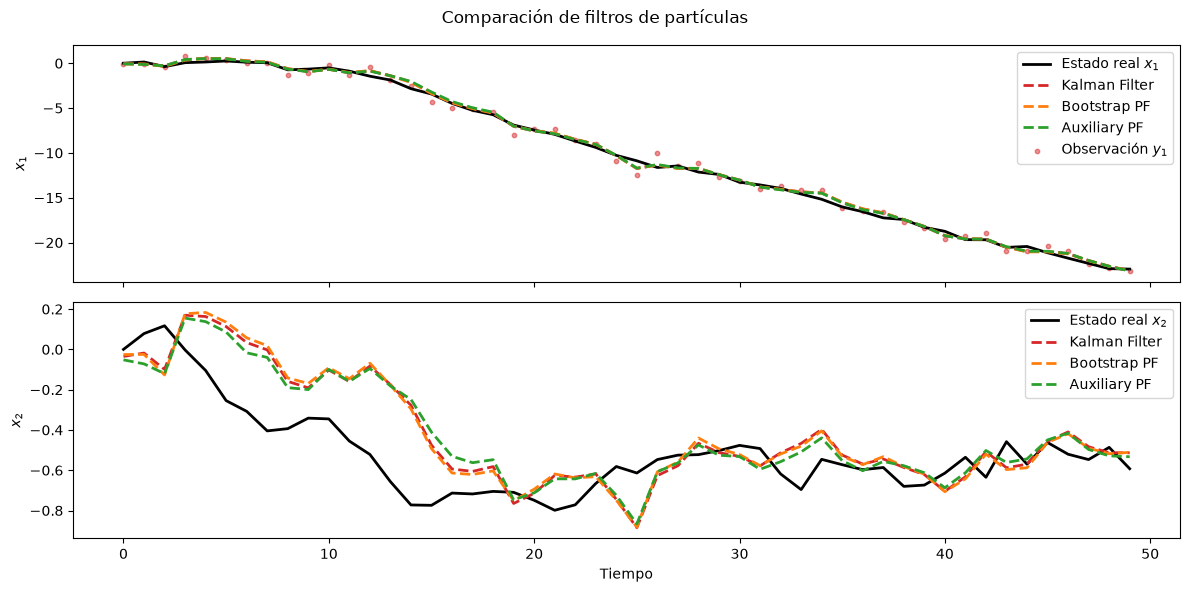

In [11]:
# Plotear resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"]
}


plot_results(x_true, y_obs, estimates)

- Representacion de la incertidumbre

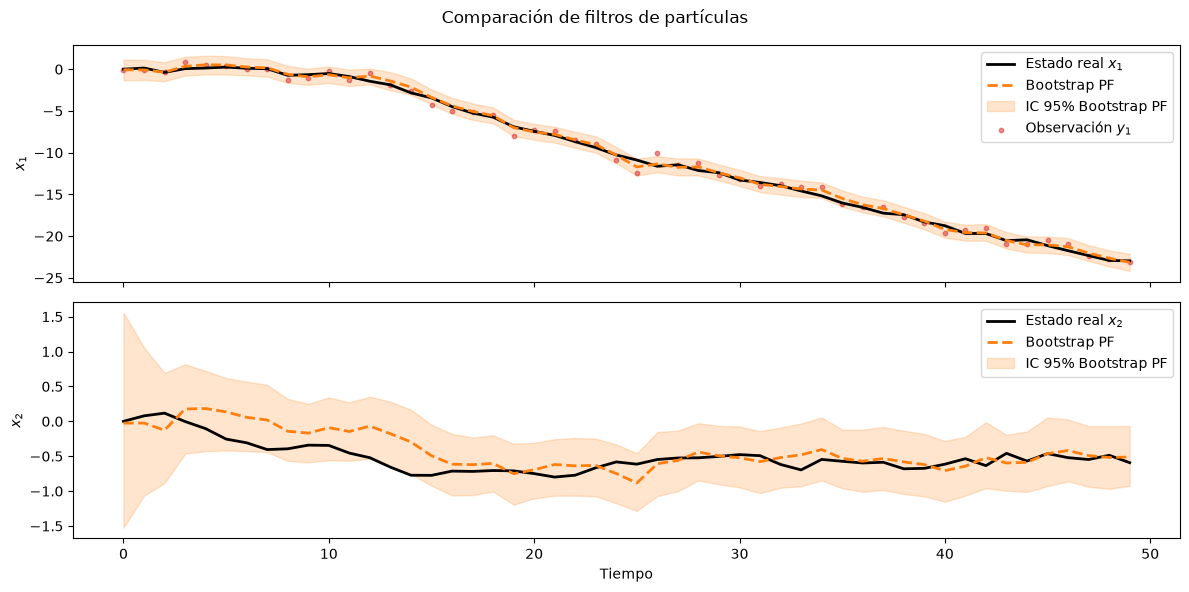

In [12]:
estimates_bpf = { "Bootstrap PF": est_bpf["estimates"] }
confidence_intervals_bpf = { "Bootstrap PF": est_bpf["intervals"] }

plot_results(x_true, y_obs, estimates_bpf, confidence_intervals_bpf)

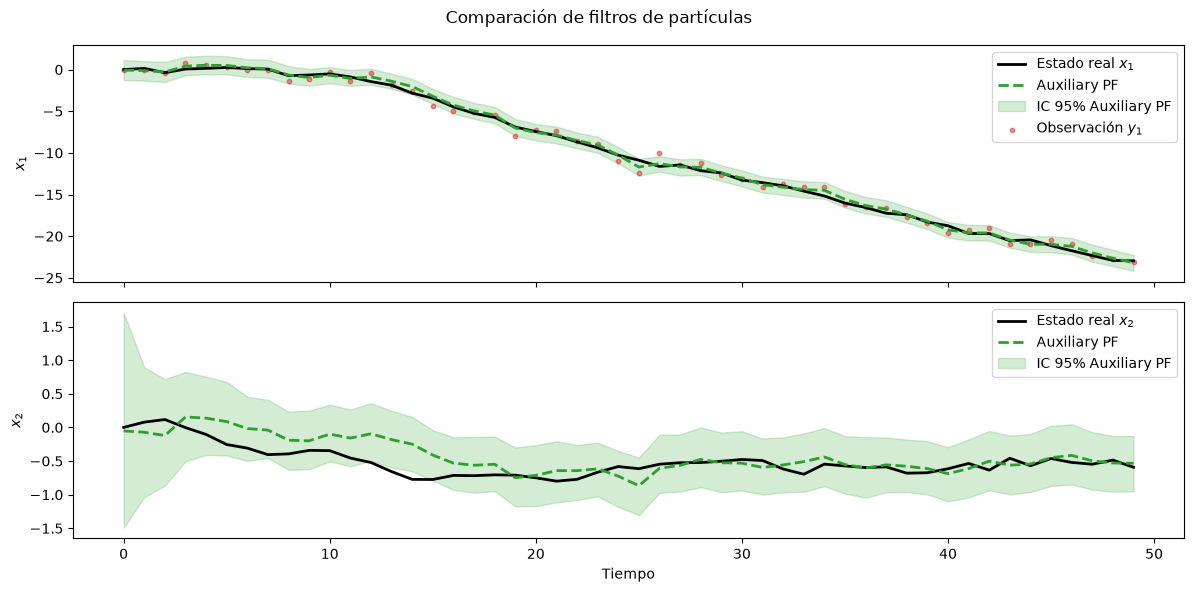

In [13]:
estimates_apf = { "Auxiliary PF": est_apf["estimates"] }
confidence_intervals_apf = { "Auxiliary PF": est_apf["intervals"] }

plot_results(x_true, y_obs, estimates_apf, confidence_intervals_apf)

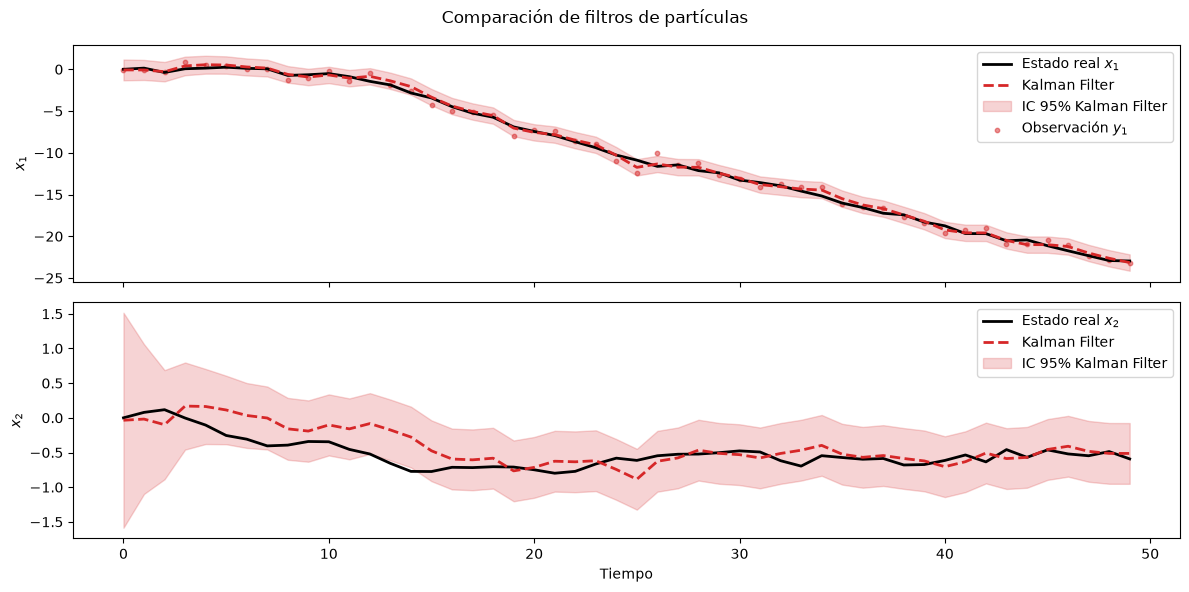

In [14]:
estimates_kf = { "Kalman Filter": est_kf["estimates"] }
confidence_intervals_kf = { "Kalman Filter": est_kf["intervals"] }

plot_results(x_true, y_obs, estimates_kf, confidence_intervals_kf)

Ahora, para comparar, se realizan los filtros de particulas pero sin realizar re-muestreo

In [15]:
bf_no_resample = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bf_no_resample.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_bf_no_resample = bf_no_resample.run_filter(y_obs)

In [16]:
apf_no_resample = AuxiliaryParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

apf_no_resample.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_apf_no_resample = apf_no_resample.run_filter(y_obs)

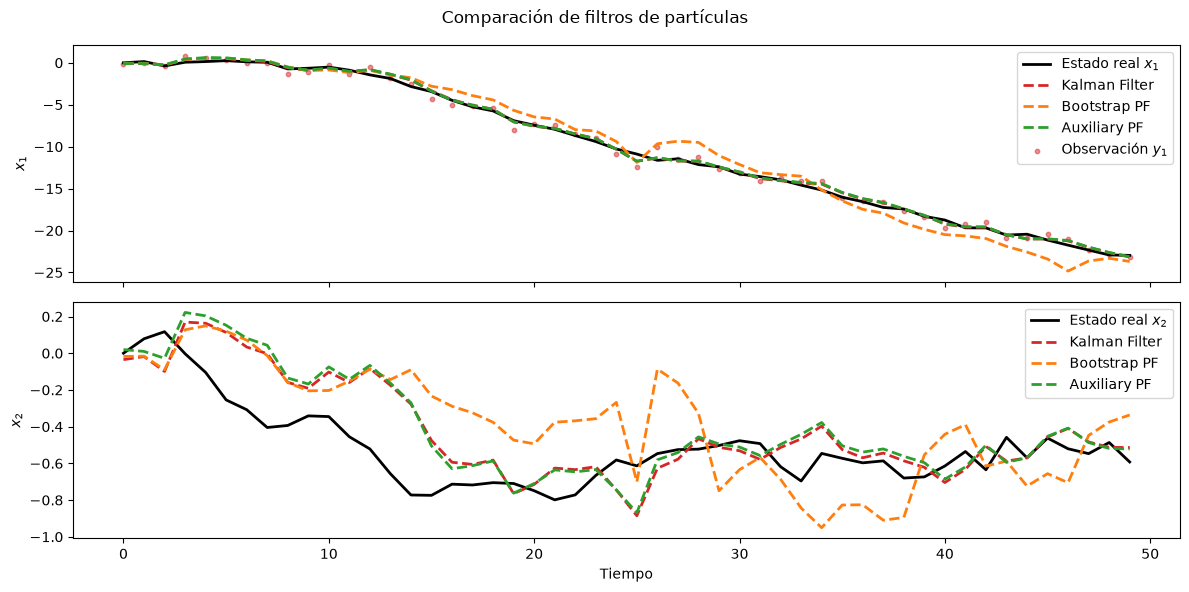

In [17]:
# Plotear resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bf_no_resample["estimates"],
    "Auxiliary PF": est_apf_no_resample["estimates"]
}


plot_results(x_true, y_obs, estimates)

### Ejemplo 2D -> Observación 2D

$$
A = \begin{bmatrix}
1 &1 \\
0 &1
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1 &0 \\
0 &1
\end{bmatrix}
\;\;
Q = \begin{bmatrix}
0.1 &0 \\
0 &0.01
\end{bmatrix}
\;\;
R = \begin{bmatrix}
0.5 &0 \\
0 &0.2
\end{bmatrix}
$$

In [18]:
# Definicion sistema

A = np.array([
    [1., 1.],
    [0., 1.]
])

H = np.eye(2)

Q = np.array([
    [0.1, 0.0],
    [0.0, 0.01]
])

R = np.array([
    [0.5, 0.0],
    [0.0, 0.2]
])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [19]:
transition = GaussianTransitionModel(f, Q)
observation = GaussianObservationModel(h, R)

In [20]:
# Simulacion
T = 50
x0 = np.array([0.0, 0.0])

x_true, y_obs = system_simulation(transition, observation, x0, T)

- Bootstrap Particle Filter

In [21]:
# Inicializacion Bootstrap Filter
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

# Ejecucion Bootstrap Particle Filter
est_bpf = bpf.run_filter(y_obs, resample_threshold=500)

- Auxiliary Particle Filter

In [22]:
# Inicializacion Auxiliary Particle Filter
apf = AuxiliaryParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

# Ejecucion Auxiliary Particle Filter
est_apf = apf.run_filter(y_obs, resample_threshold=500)

- Kalman Filter

In [23]:
x0 = np.array([0.0, 0.0])
P0 = np.eye(2)

kf = KalmanFilter(A, H, Q, R, x0, P0)

est_kf = kf.run_filter(y_obs)

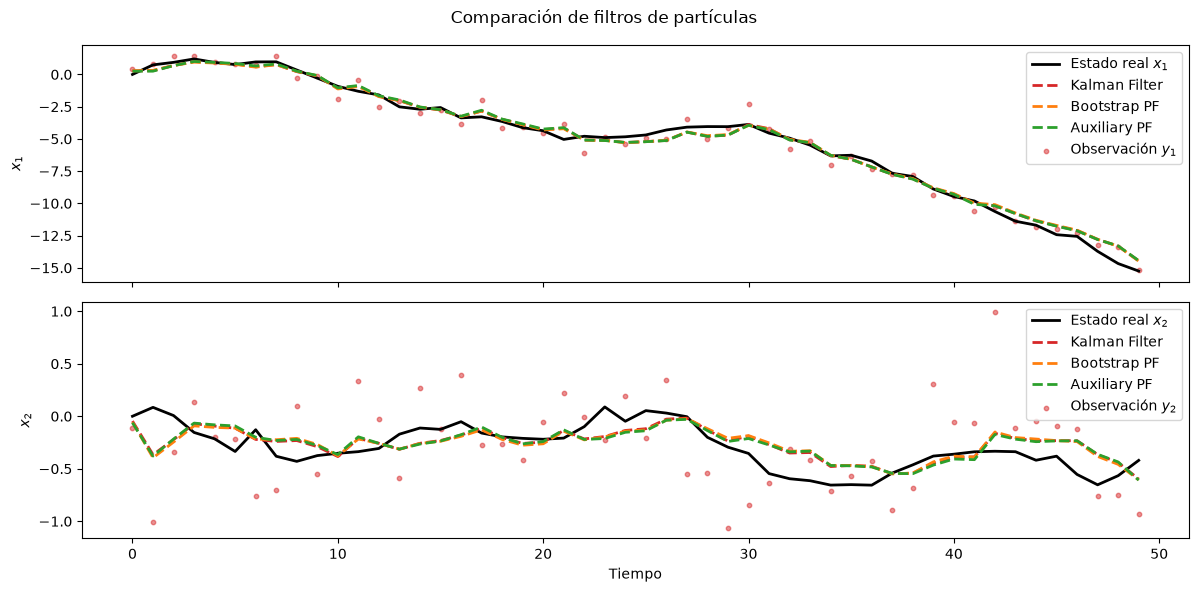

In [24]:
# Plotear resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"]
}


plot_results(x_true, y_obs, estimates)

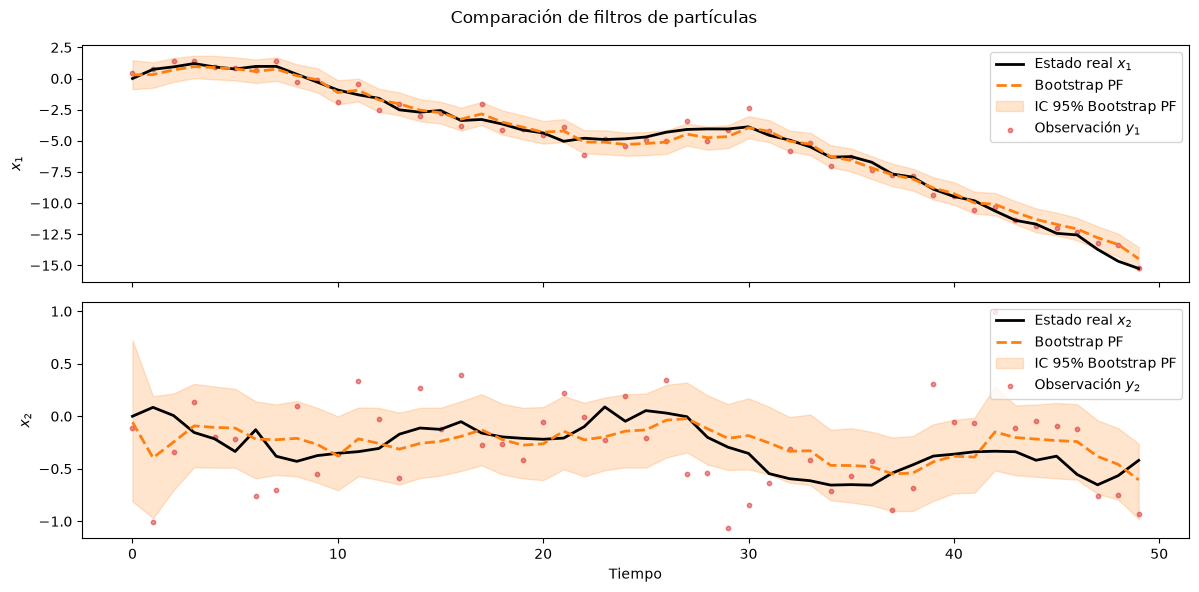

In [25]:
estimates_bpf = { "Bootstrap PF": est_bpf["estimates"] }
confidence_intervals_bpf = { "Bootstrap PF": est_bpf["intervals"] }

plot_results(x_true, y_obs, estimates_bpf, confidence_intervals_bpf)

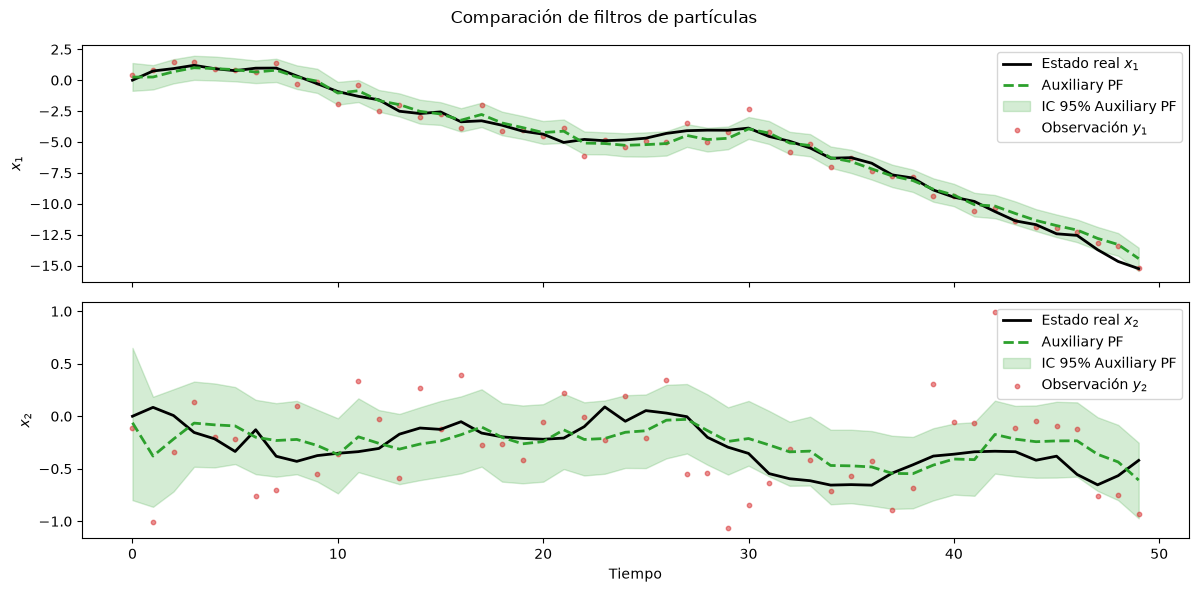

In [26]:
estimates_apf = { "Auxiliary PF": est_apf["estimates"] }
confidence_intervals_apf = { "Auxiliary PF": est_apf["intervals"] }

plot_results(x_true, y_obs, estimates_apf, confidence_intervals_apf)

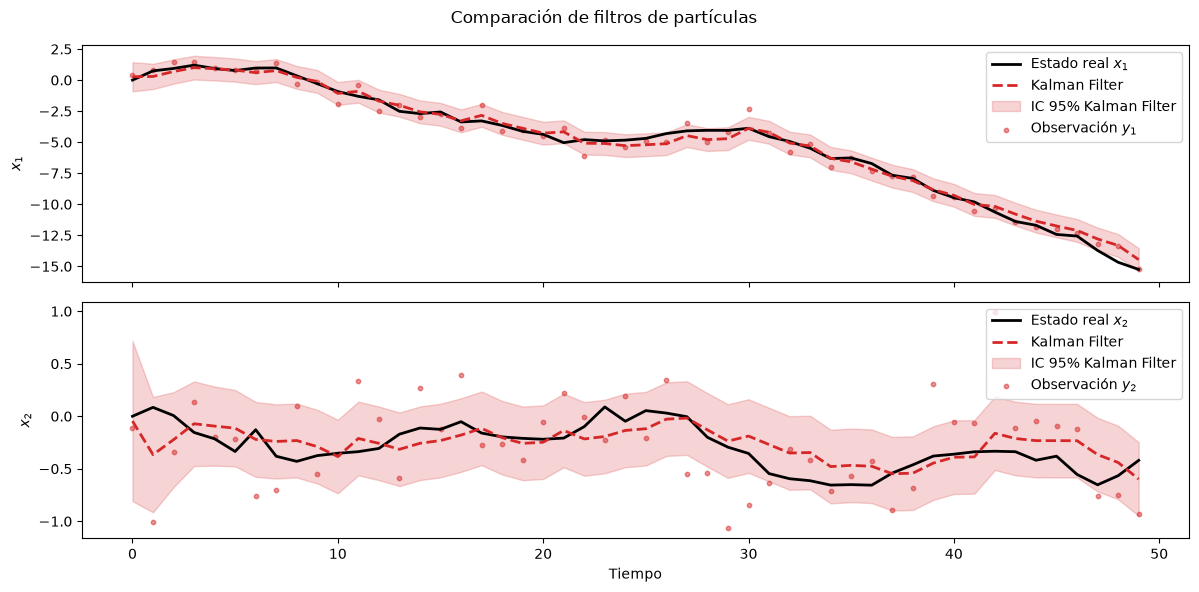

In [27]:
estimates_kf = { "Kalman Filter": est_kf["estimates"] }
confidence_intervals_kf = { "Kalman Filter": est_kf["intervals"] }

plot_results(x_true, y_obs, estimates_kf, confidence_intervals_kf)

Para este último caso, se va a comparar el rendimiento del filtrado sin realizar el re-muestreo (se utiliza la misma simulación anterior)

In [28]:
# Inicializacion Bootstrap Filter
bpf_no_resample = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf_no_resample.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

# Ejecucion Bootstrap Particle Filter
est_bpf_no_resample = bpf_no_resample.run_filter(y_obs)

In [29]:
# Inicializacion Auxiliary Particle Filter
apf_no_resample = AuxiliaryParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

apf_no_resample.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

# Ejecucion Auxiliary Particle Filter
est_apf_no_resample = apf_no_resample.run_filter(y_obs)

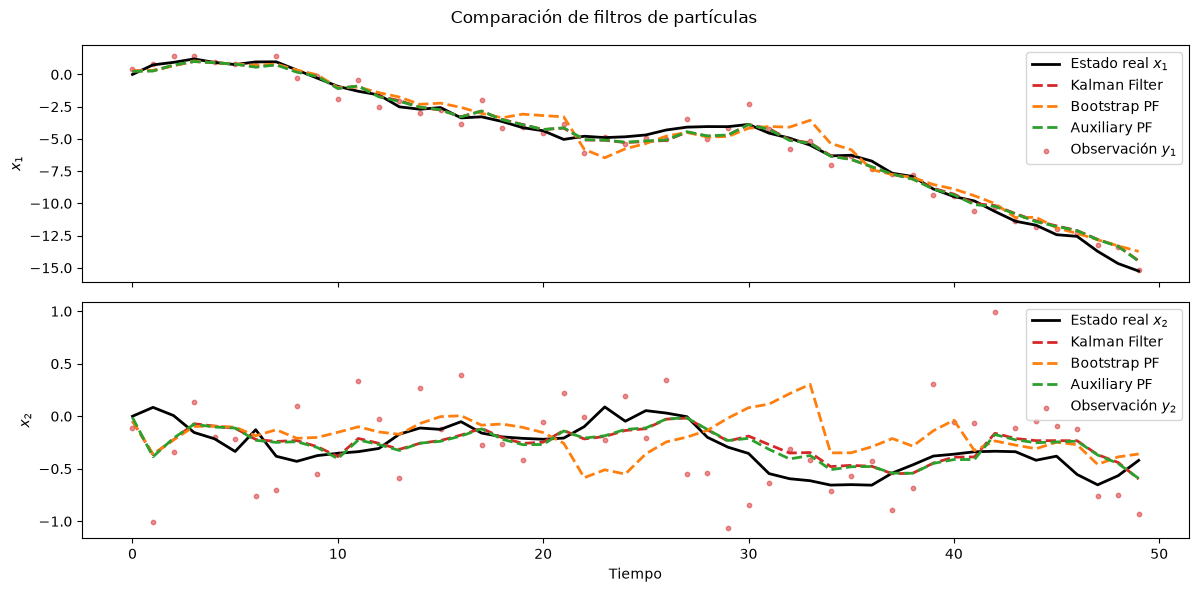

In [30]:
# Plotear resultados
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf_no_resample["estimates"],
    "Auxiliary PF": est_apf_no_resample["estimates"]
}


plot_results(x_true, y_obs, estimates)

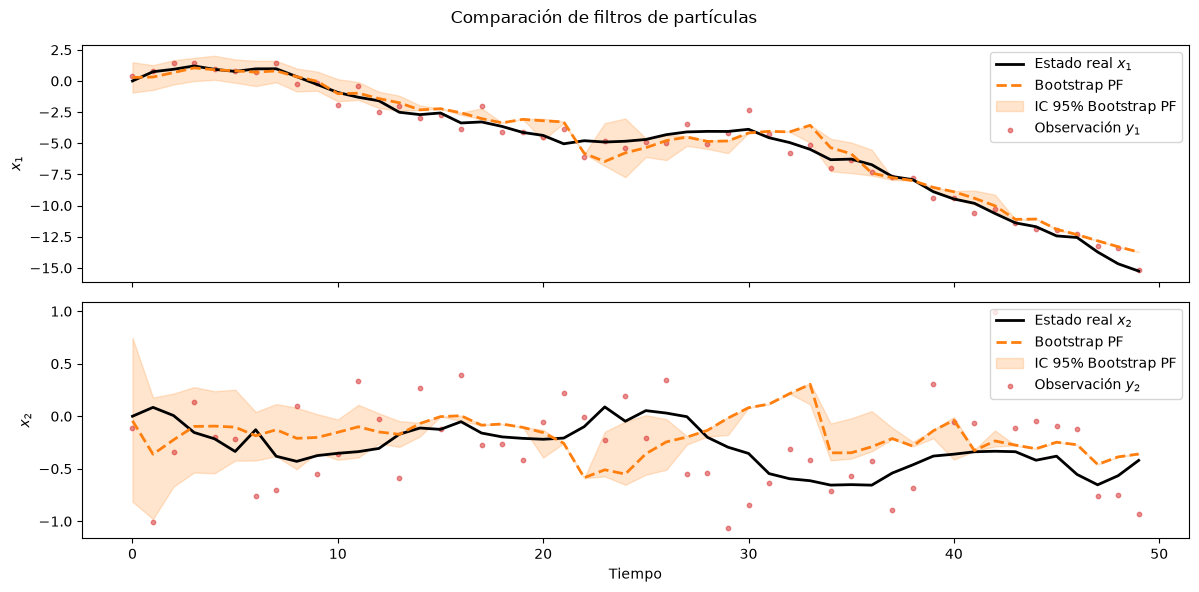

In [31]:
estimates_bpf_no_resample = { "Bootstrap PF": est_bpf_no_resample["estimates"] }
confidence_intervals_bpf_no_resample = { "Bootstrap PF": est_bpf_no_resample["intervals"] }

plot_results(x_true, y_obs, estimates_bpf_no_resample, confidence_intervals_bpf_no_resample)

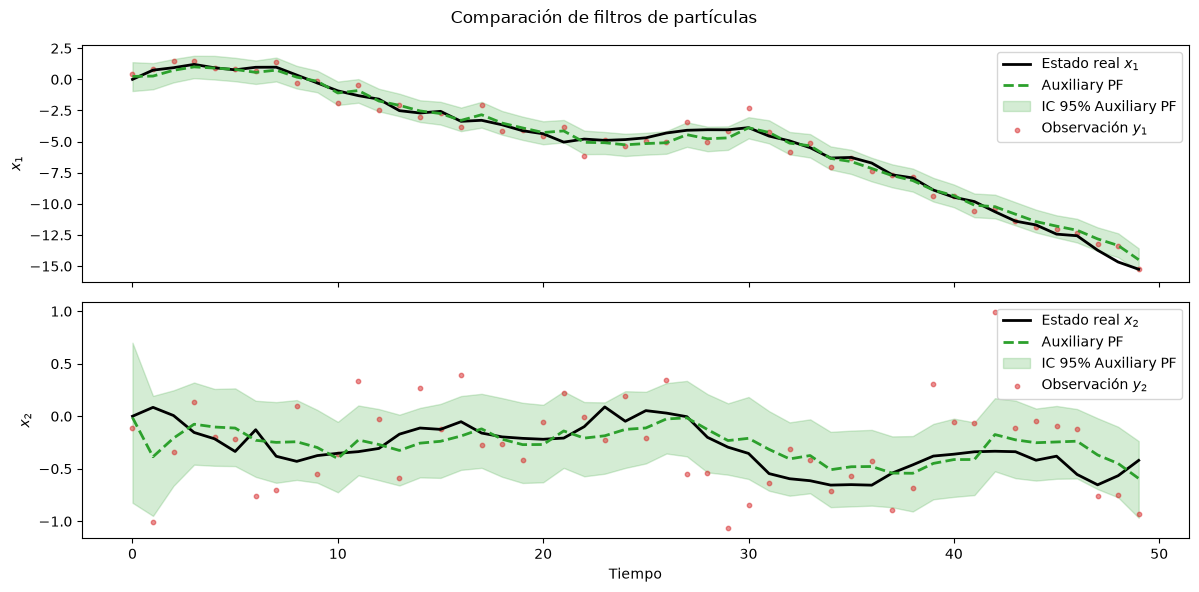

In [32]:
estimates_apf_no_resample = { "Auxiliary PF": est_apf_no_resample["estimates"] }
confidence_intervals_apf_no_resample = { "Auxiliary PF": est_apf_no_resample["intervals"] }

plot_results(x_true, y_obs, estimates_apf_no_resample, confidence_intervals_apf_no_resample)

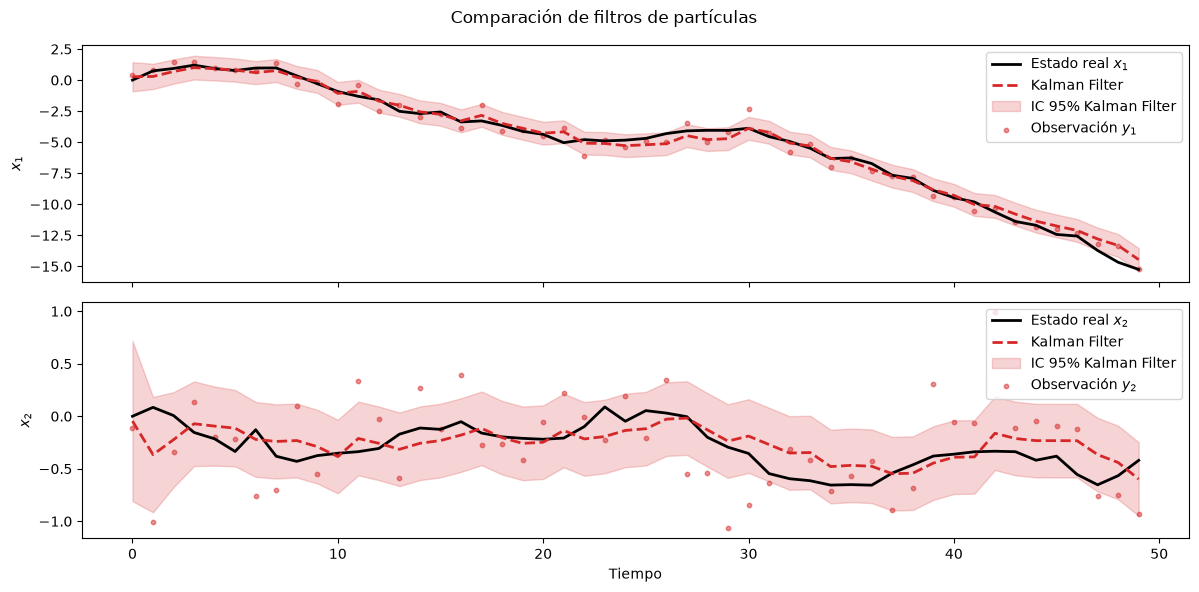

In [33]:
estimates_kf = { "Kalman Filter": est_kf["estimates"] }
confidence_intervals_kf = { "Kalman Filter": est_kf["intervals"] }

plot_results(x_true, y_obs, estimates_kf, confidence_intervals_kf)

### Estudio de la degeneración de los pesos de las partículas

Para los resultados obtenidos en el último modelo, se va a representar el peso de las distintas partículas en tiempos fijos de los dos filtros en los casos con y sin re-muestreo.

In [34]:
from plot import plot_sorted_weights

In [36]:
plot_times = [0, 10, 20, 30, 40, 49]

- Caso con re-muestreo

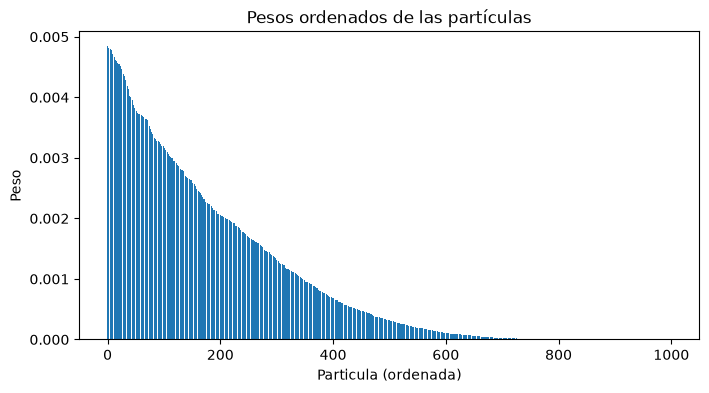

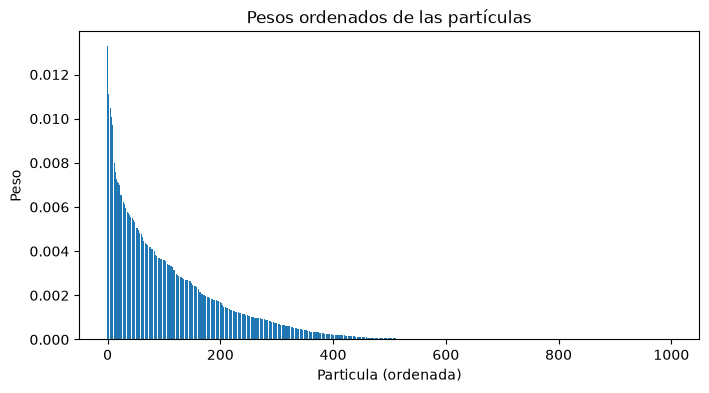

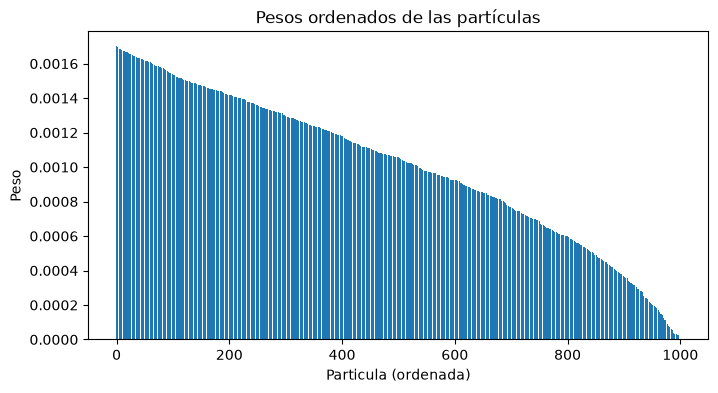

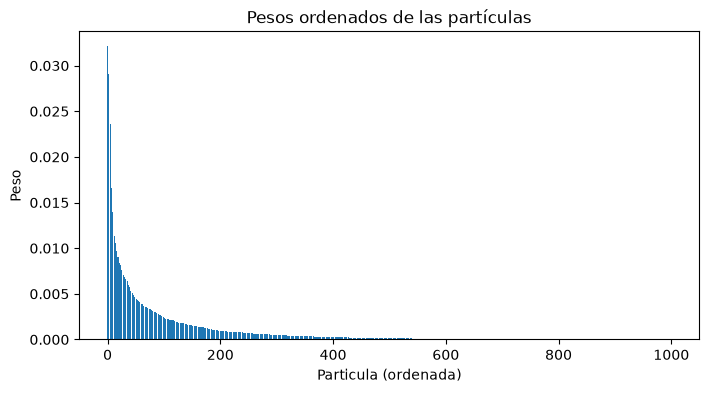

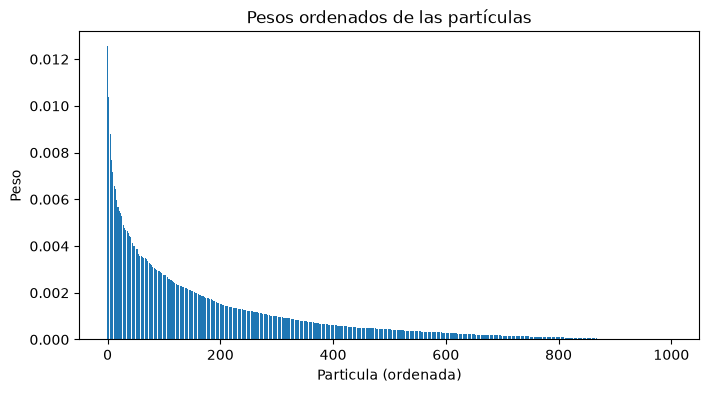

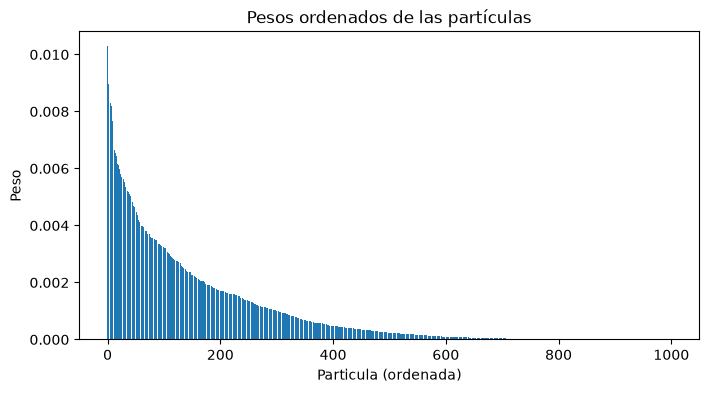

In [37]:
# Bootstrap Filter
for time in plot_times:
    plot_sorted_weights(est_bpf["weights"][time])

Aunque en los tiempos escogidos no se ha tenido una gráfica con los pesos uniformes (porque en los tiempos muestrados so se logra) se puede ver que en ciertos momentos la distribución pasa a una distribución más uniforme teniendo una más asimétrica antes. Esto indica que entre esos dos tiempos se ha realizado un remuestreo.

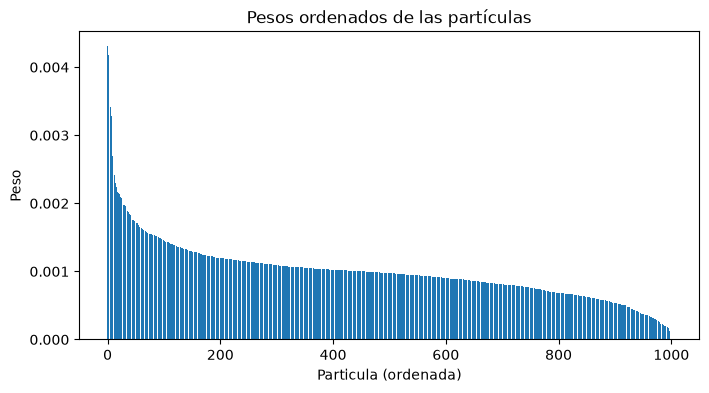

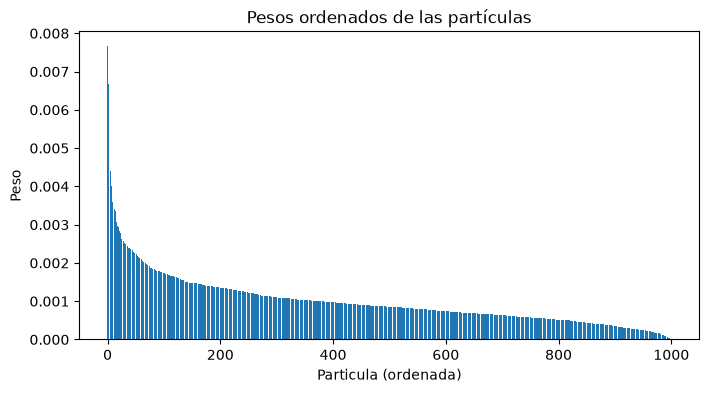

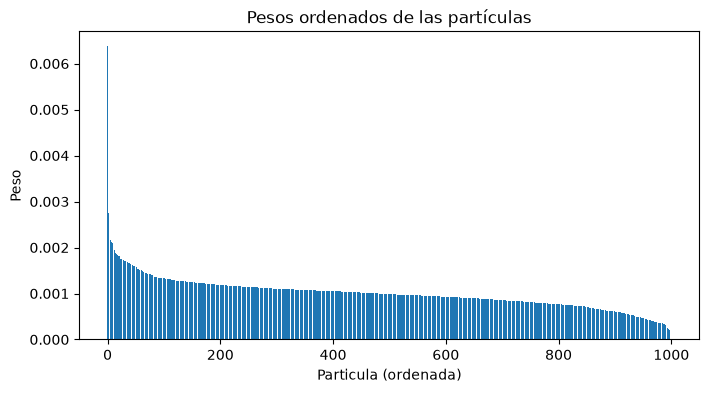

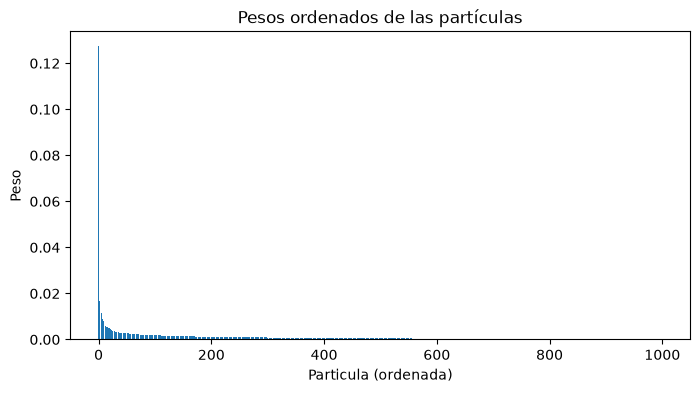

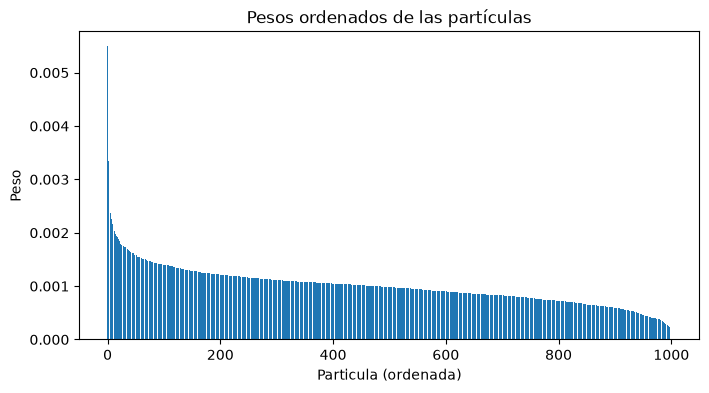

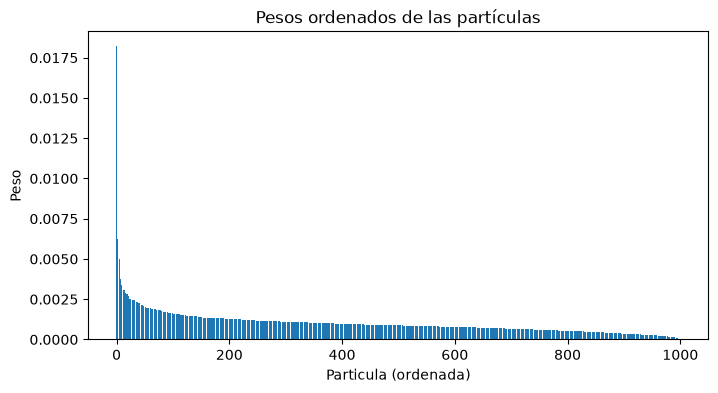

In [ ]:
# Auxiliary Particle Filter
for time in plot_times:
    plot_sorted_weights(est_apf["weights"][time])

De nuevo, se reccupera de la degeneración de pesos y, sobre todo, se retrasa

- Sin re-muestreo

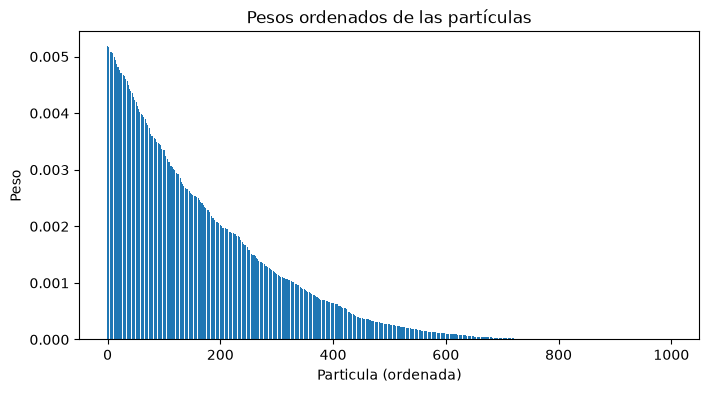

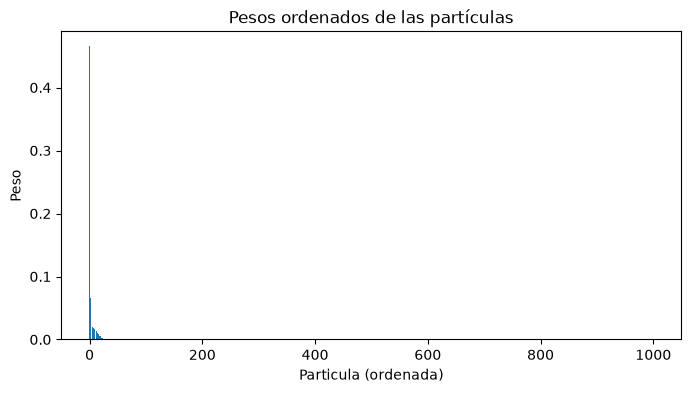

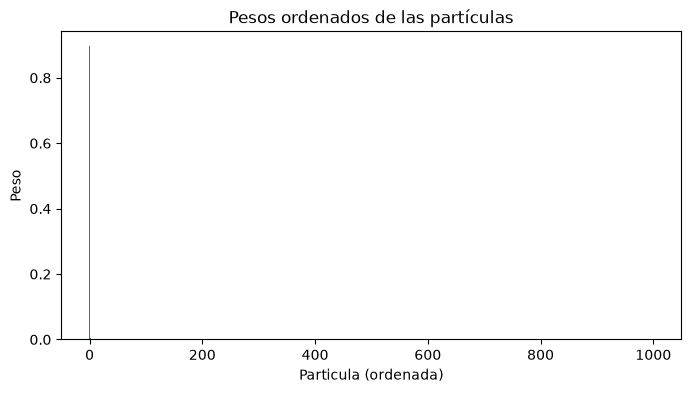

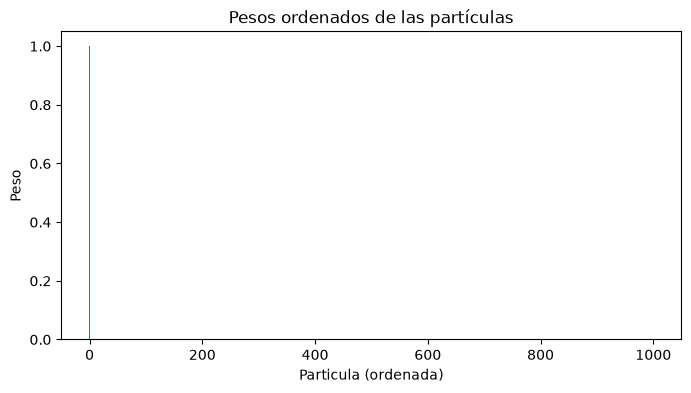

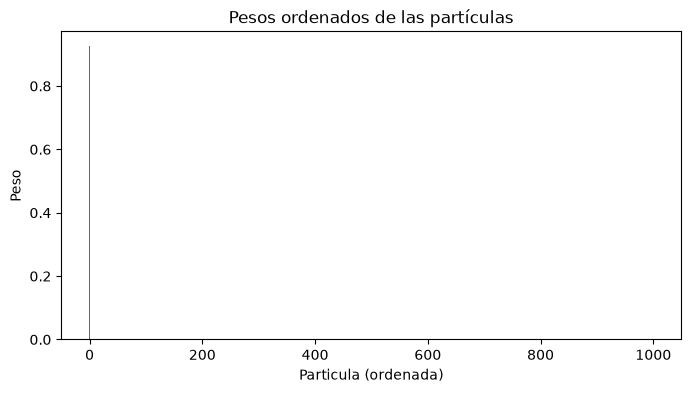

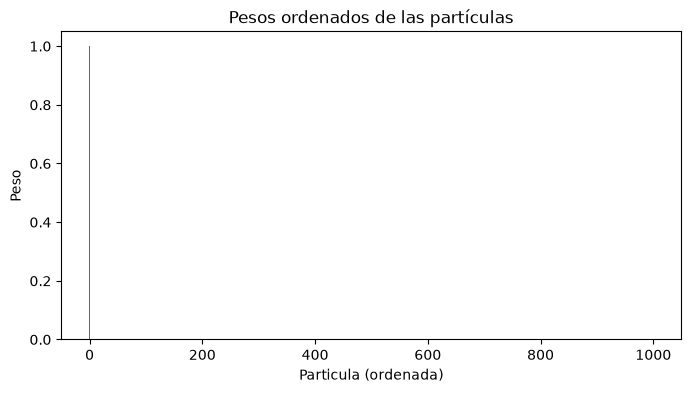

In [39]:
# Bootstrap Particle Filter
for time in plot_times:
    plot_sorted_weights(est_bpf_no_resample["weights"][time])

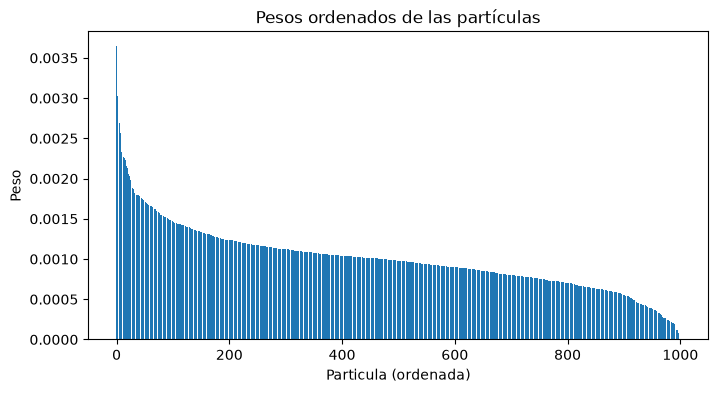

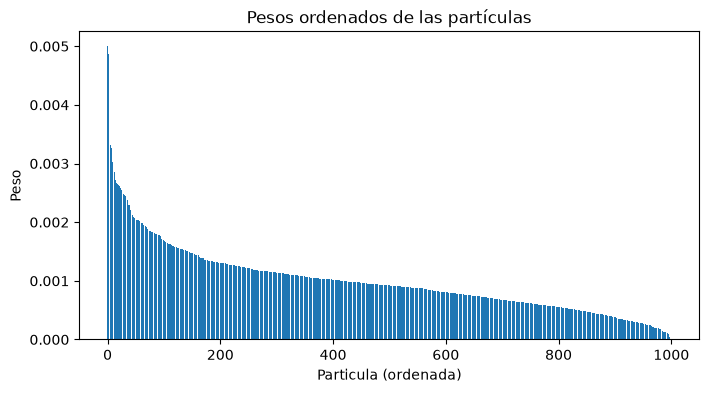

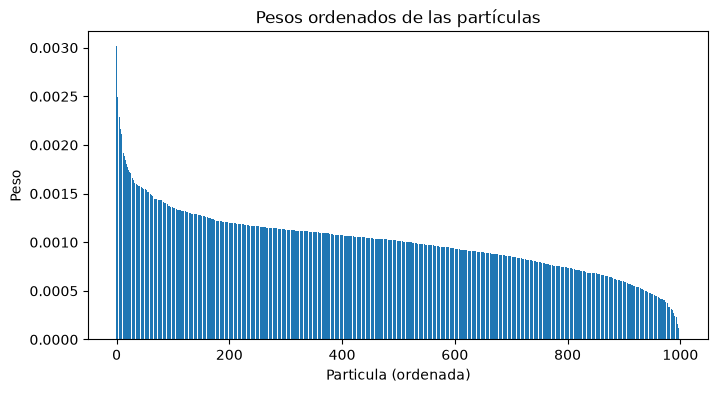

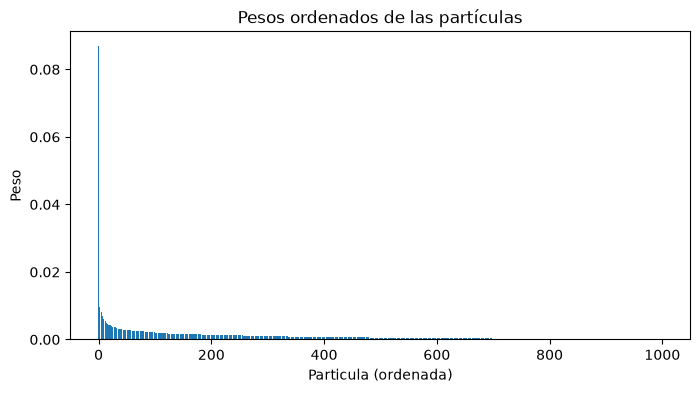

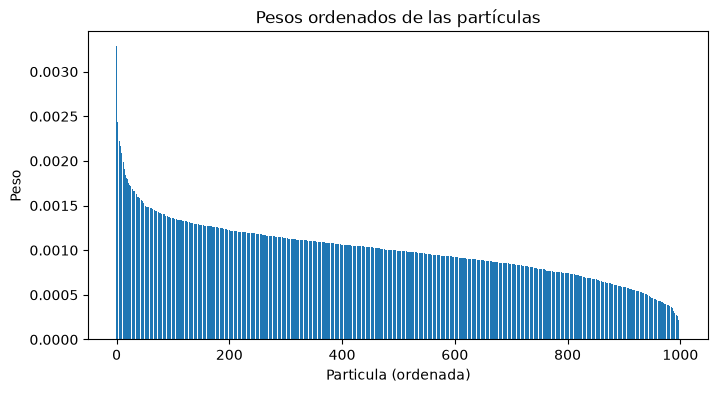

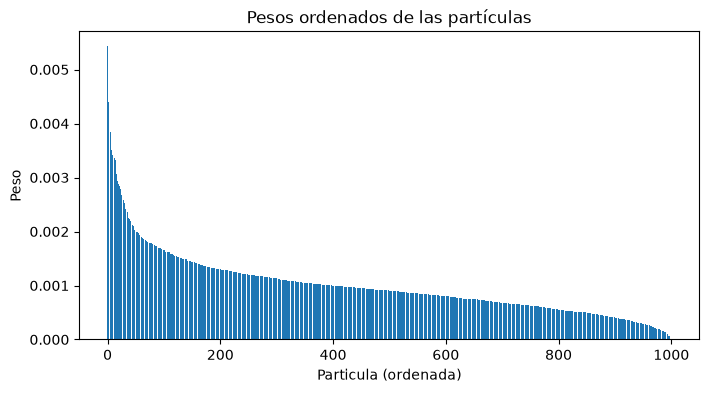

In [40]:
# Auxiliary Particle Filter
for time in plot_times:
    plot_sorted_weights(est_apf_no_resample["weights"][time])